<a href="https://colab.research.google.com/github/aldoalvaro/Kelompok3ProbStat_StatistikaDeskriptif/blob/main/AnalisisDeskriptifKel3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CELL 1 - Import Library

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Library berhasil di-import.")

Library berhasil di-import.


CELL 2 - Upload dan Muat Data

In [38]:
from google.colab import files
uploaded = files.upload()

# Ambil nama file yang di-upload
FILE_PATH = list(uploaded.keys())[0]
df = pd.read_excel(FILE_PATH, sheet_name="Data")

print("File:", FILE_PATH)
print("Shape:", df.shape)
print("Kolom:", list(df.columns))
df.head()

Saving 3TIE_03_PairProgramming (1).xlsx to 3TIE_03_PairProgramming (1) (2).xlsx
File: 3TIE_03_PairProgramming (1) (2).xlsx
Shape: (138, 7)
Kolom: ['id', 'site', 'gender', 'group', 'pp_t1', 'pp_t2', 'delta_pp']


,id,site,gender,group,pp_t1,pp_t2,delta_pp
0,259367,Seville,man,exp,8.0000,2.7500,-5.2500
1,294579,Seville,man,ctrl,8.5000,7.7500,-0.7500
2,317301,Seville,man,exp,8.7500,7.7500,-1.0000
3,209854,Seville,man,ctrl,6.2500,7.5000,1.2500
4,812312,Seville,man,exp,7.0000,7.5000,0.5000


CELL 3 - Validasi Data

In [39]:
print("=" * 70)
print("1. VALIDASI DATA")
print("=" * 70)

# 1.1 Jumlah peserta
print("\n1.1 Jumlah peserta")
print(f"  Jumlah baris          : {len(df)}")
print(f"  Seville               : {(df['site'] == 'Seville').sum()}")
print(f"  Berkeley              : {(df['site'] == 'Berkeley').sum()}")
print(f"  Total                 : {(df['site'] == 'Seville').sum() + (df['site'] == 'Berkeley').sum()}")

# 1.2 Kolom wajib & tipe data
print("\n1.2 Kolom wajib & tipe data")
wajib = ["id", "site", "pp_t1", "pp_t2", "delta_pp"]
print(f"  Semua kolom wajib ada : {all(c in df.columns for c in wajib)}")
print(df.dtypes)

# 1.3 Missing value
print("\n1.3 Missing value")
print(df.isnull().sum())
print(f"  Total missing         : {df.isnull().sum().sum()}")

# 1.4 Rentang nilai pp
print("\n1.4 Rentang nilai pp (harus 0–10)")
print(f"  pp_t1 min/max         : {df['pp_t1'].min()} / {df['pp_t1'].max()}")
print(f"  pp_t2 min/max         : {df['pp_t2'].min()} / {df['pp_t2'].max()}")
print(f"  pp_t1 di luar 0–10    : {((df['pp_t1'] < 0) | (df['pp_t1'] > 10)).sum()}")
print(f"  pp_t2 di luar 0–10    : {((df['pp_t2'] < 0) | (df['pp_t2'] > 10)).sum()}")

# 1.5 Verifikasi delta_pp
print("\n1.5 Verifikasi delta_pp = pp_t2 − pp_t1")
delta_hitung = df["pp_t2"] - df["pp_t1"]
selisih = (df["delta_pp"] - delta_hitung).abs()
print(f"  Maksimum selisih      : {selisih.max()}")
print(f"  Baris tidak cocok     : {(selisih > 1e-10).sum()}")

# 1.6 Duplikasi & keunikan id
print("\n1.6 Duplikasi & keunikan id")
print(f"  Duplikat baris penuh  : {df.duplicated().sum()}")
print(f"  Duplikat id           : {df['id'].duplicated().sum()}")
print(f"  id unik global        : {df['id'].nunique() == len(df)}")

site_id = df["site"].astype(str) + "_" + df["id"].astype(str)
print(f"  Duplikat site–id      : {site_id.duplicated().sum()}")

id_sev = set(df.loc[df["site"] == "Seville", "id"])
id_ber = set(df.loc[df["site"] == "Berkeley", "id"])
print(f"  Id bentrok antar site : {len(id_sev & id_ber)}")

print("\n→ Data valid dan siap untuk analisis deskriptif.")

1. VALIDASI DATA

1.1 Jumlah peserta
  Jumlah baris          : 138
  Seville               : 92
  Berkeley              : 46
  Total                 : 138

1.2 Kolom wajib & tipe data
  Semua kolom wajib ada : True
id            int64
site         object
gender       object
group        object
pp_t1       float64
pp_t2       float64
delta_pp    float64
dtype: object

1.3 Missing value
id          0
site        0
gender      0
group       0
pp_t1       0
pp_t2       0
delta_pp    0
dtype: int64
  Total missing         : 0

1.4 Rentang nilai pp (harus 0–10)
  pp_t1 min/max         : 1.0 / 10.0
  pp_t2 min/max         : 0.0 / 10.0
  pp_t1 di luar 0–10    : 0
  pp_t2 di luar 0–10    : 0

1.5 Verifikasi delta_pp = pp_t2 − pp_t1
  Maksimum selisih      : 0.0
  Baris tidak cocok     : 0

1.6 Duplikasi & keunikan id
  Duplikat baris penuh  : 0
  Duplikat id           : 0
  id unik global        : True
  Duplikat site–id      : 0
  Id bentrok antar site : 0

→ Data valid dan siap untuk analisis

CELL 4 - Statistik Deskriptif Variabel Utama

In [40]:
print("=" * 70)
print("2. STATISTIKA DESKRIPTIF VARIABEL UTAMA")
print("=" * 70)

# Pastikan numerik
for col in ["pp_t1", "pp_t2", "delta_pp"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

def buat_stats(series, nama):
    """Statistik deskriptif lengkap (sesuai gaya contoh dosen)"""
    s = series.describe()
    s["Standard Error"] = series.sem()
    s["Median"]         = series.median()
    s["Mode"]           = series.mode().iloc[0] if not series.mode().empty else np.nan
    s["variance"]       = series.var()
    s["range"]          = series.max() - series.min()
    s["skewness"]       = series.skew()
    s["kurtosis"]       = series.kurtosis()
    s.name = nama
    return s

stats_t1    = buat_stats(df["pp_t1"], "pp_t1")
stats_t2    = buat_stats(df["pp_t2"], "pp_t2")
stats_delta = buat_stats(df["delta_pp"], "delta_pp")

# Tampilkan terpisah per variabel (mirip contoh dosen)
print("\n--- Statistik pp_t1 (Persepsi setelah Sesi 1) ---")
print(stats_t1.round(4))

print("\n--- Statistik pp_t2 (Persepsi setelah Sesi 2) ---")
print(stats_t2.round(4))

print("\n--- Statistik delta_pp (Perubahan Persepsi) ---")
print(stats_delta.round(4))

# Tabel gabungan (opsional, untuk perbandingan cepat)
print("\n--- Tabel Gabungan (untuk perbandingan) ---")
tabel_stats = pd.DataFrame({
    "pp_t1": stats_t1,
    "pp_t2": stats_t2,
    "delta_pp": stats_delta
})
urutan = ["count", "mean", "std", "min", "25%", "50%", "75%", "max",
          "Standard Error", "Median", "Mode", "variance", "range", "skewness", "kurtosis"]
print(tabel_stats.reindex(urutan).round(4))

2. STATISTIKA DESKRIPTIF VARIABEL UTAMA

--- Statistik pp_t1 (Persepsi setelah Sesi 1) ---
count            138.0000
mean               6.6467
std                2.1952
min                1.0000
25%                5.0000
50%                7.2500
75%                8.5000
max               10.0000
Standard Error     0.1869
Median             7.2500
Mode               7.5000
variance           4.8191
range              9.0000
skewness          -0.7189
kurtosis          -0.1849
Name: pp_t1, dtype: float64

--- Statistik pp_t2 (Persepsi setelah Sesi 2) ---
count            138.0000
mean               6.8714
std                2.2230
min                0.0000
25%                5.2500
50%                7.1250
75%                8.7500
max               10.0000
Standard Error     0.1892
Median             7.1250
Mode               9.0000
variance           4.9418
range             10.0000
skewness          -0.7051
kurtosis           0.1842
Name: pp_t2, dtype: float64

--- Statistik delta_p

CELL 5 - Frekuensi Kategori Perubahan (delta_pp)

In [41]:
print("=" * 70)
print("3. FREKUENSI PERUBAHAN PERSEPSI (delta_pp)")
print("=" * 70)

def kategori_delta(x):
    if x > 0:
        return "Positif (naik)"
    elif x < 0:
        return "Negatif (turun)"
    else:
        return "Nol (tetap)"

df["kategori_delta"] = df["delta_pp"].apply(kategori_delta)

freq_delta = df["kategori_delta"].value_counts().reindex(
    ["Positif (naik)", "Negatif (turun)", "Nol (tetap)"]
)
freq_delta_pct = (freq_delta / len(df) * 100).round(2)

tabel_delta = pd.DataFrame({
    "Frekuensi": freq_delta,
    "Persentase (%)": freq_delta_pct
})
print(tabel_delta)
print(f"\nTotal: {freq_delta.sum()} (harus = {len(df)})")

3. FREKUENSI PERUBAHAN PERSEPSI (delta_pp)
                 Frekuensi  Persentase (%)
kategori_delta                            
Positif (naik)          65         47.1000
Negatif (turun)         54         39.1300
Nol (tetap)             19         13.7700

Total: 138 (harus = 138)


CELL 6 - Frekuensi Variabel Kategorik

In [42]:
print("=" * 70)
print("4. FREKUENSI VARIABEL KATEGORIK")
print("=" * 70)

for col in ["site", "gender", "group"]:
    print(f"\n{col}:")
    vc = df[col].value_counts()
    pct = (vc / len(df) * 100).round(2)
    print(pd.DataFrame({"Frekuensi": vc, "Persentase (%)": pct}))

4. FREKUENSI VARIABEL KATEGORIK

site:
          Frekuensi  Persentase (%)
site                               
Seville          92         66.6700
Berkeley         46         33.3300

gender:
            Frekuensi  Persentase (%)
gender                               
man                96         69.5700
woman              41         29.7100
non-binary          1          0.7200

group:
       Frekuensi  Persentase (%)
group                           
exp           69         50.0000
ctrl          69         50.0000


CELL 7 - Ringkasan Mean per Lokasi

In [43]:
print("=" * 70)
print("5. RINGKASAN MEAN ± STD PER LOKASI")
print("=" * 70)

ringkas_site = df.groupby("site")[["pp_t1", "pp_t2", "delta_pp"]].agg(["mean", "std", "count"])
print(ringkas_site.round(3))

5. RINGKASAN MEAN ± STD PER LOKASI
          pp_t1               pp_t2              delta_pp             
           mean    std count   mean    std count     mean    std count
site                                                                  
Berkeley 5.4950 2.1650    46 6.1960 2.4110    46   0.7010 2.6930    46
Seville  7.2230 1.9830    92 7.2090 2.0540    92  -0.0140 1.9810    92


CELL 8 - Persentase Meningkat per Lokasi

In [44]:
print("=" * 70)
print("5b. PERSENTASE MENINGKAT PER LOKASI (untuk Tabel 4.5)")
print("=" * 70)

# Hitung % meningkat (delta_pp > 0) per site
ringkas = df.groupby("site").agg(
    N=("id", "count"),
    mean_pp_t1=("pp_t1", "mean"),
    mean_pp_t2=("pp_t2", "mean"),
    mean_delta=("delta_pp", "mean"),
    n_meningkat=("delta_pp", lambda x: (x > 0).sum())
).reset_index()

ringkas["pct_meningkat"] = (ringkas["n_meningkat"] / ringkas["N"] * 100).round(1)

print(ringkas.to_string(index=False))

5b. PERSENTASE MENINGKAT PER LOKASI (untuk Tabel 4.5)
    site  N  mean_pp_t1  mean_pp_t2  mean_delta  n_meningkat  pct_meningkat
Berkeley 46      5.4946      6.1957      0.7011           25        54.3000
 Seville 92      7.2228      7.2092     -0.0136           40        43.5000


CELL 9 - Histogram pp_t1, pp_t2, dan delta_pp

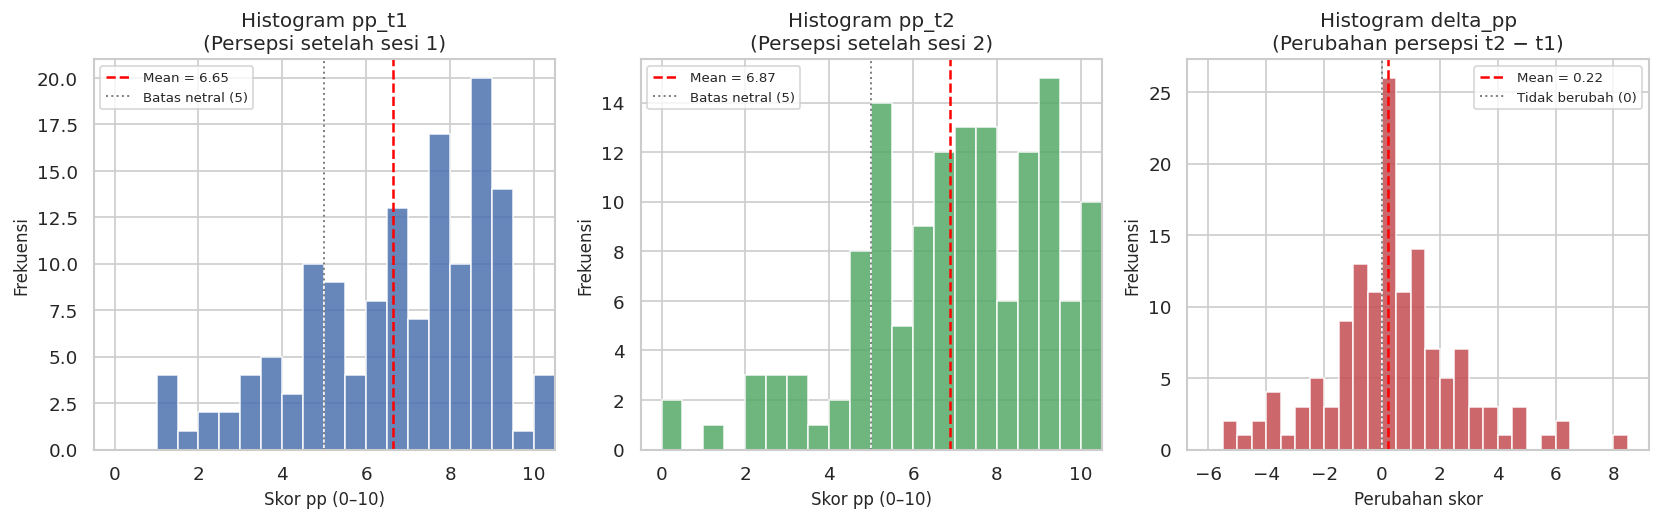

In [45]:
warna_pp = ["#4C72B0", "#55A868", "#C44E52"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

# pp_t1
axes[0].hist(df["pp_t1"], bins=np.arange(0, 11.5, 0.5), color=warna_pp[0],
             edgecolor="white", alpha=0.85)
axes[0].axvline(df["pp_t1"].mean(), color="red", linestyle="--", linewidth=1.5,
                label=f"Mean = {df['pp_t1'].mean():.2f}")
axes[0].axvline(5, color="gray", linestyle=":", linewidth=1.2, label="Batas netral (5)")
axes[0].set_title("Histogram pp_t1\n(Persepsi setelah sesi 1)")
axes[0].set_xlabel("Skor pp (0–10)")
axes[0].set_ylabel("Frekuensi")
axes[0].legend(fontsize=8)
axes[0].set_xlim(-0.5, 10.5)

# pp_t2
axes[1].hist(df["pp_t2"], bins=np.arange(0, 11.5, 0.5), color=warna_pp[1],
             edgecolor="white", alpha=0.85)
axes[1].axvline(df["pp_t2"].mean(), color="red", linestyle="--", linewidth=1.5,
                label=f"Mean = {df['pp_t2'].mean():.2f}")
axes[1].axvline(5, color="gray", linestyle=":", linewidth=1.2, label="Batas netral (5)")
axes[1].set_title("Histogram pp_t2\n(Persepsi setelah sesi 2)")
axes[1].set_xlabel("Skor pp (0–10)")
axes[1].set_ylabel("Frekuensi")
axes[1].legend(fontsize=8)
axes[1].set_xlim(-0.5, 10.5)

# delta_pp
axes[2].hist(df["delta_pp"], bins=np.arange(-6, 9, 0.5), color=warna_pp[2],
             edgecolor="white", alpha=0.85)
axes[2].axvline(df["delta_pp"].mean(), color="red", linestyle="--", linewidth=1.5,
                label=f"Mean = {df['delta_pp'].mean():.2f}")
axes[2].axvline(0, color="gray", linestyle=":", linewidth=1.2, label="Tidak berubah (0)")
axes[2].set_title("Histogram delta_pp\n(Perubahan persepsi t2 − t1)")
axes[2].set_xlabel("Perubahan skor")
axes[2].set_ylabel("Frekuensi")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

CELL 10 - Boxplot Individual

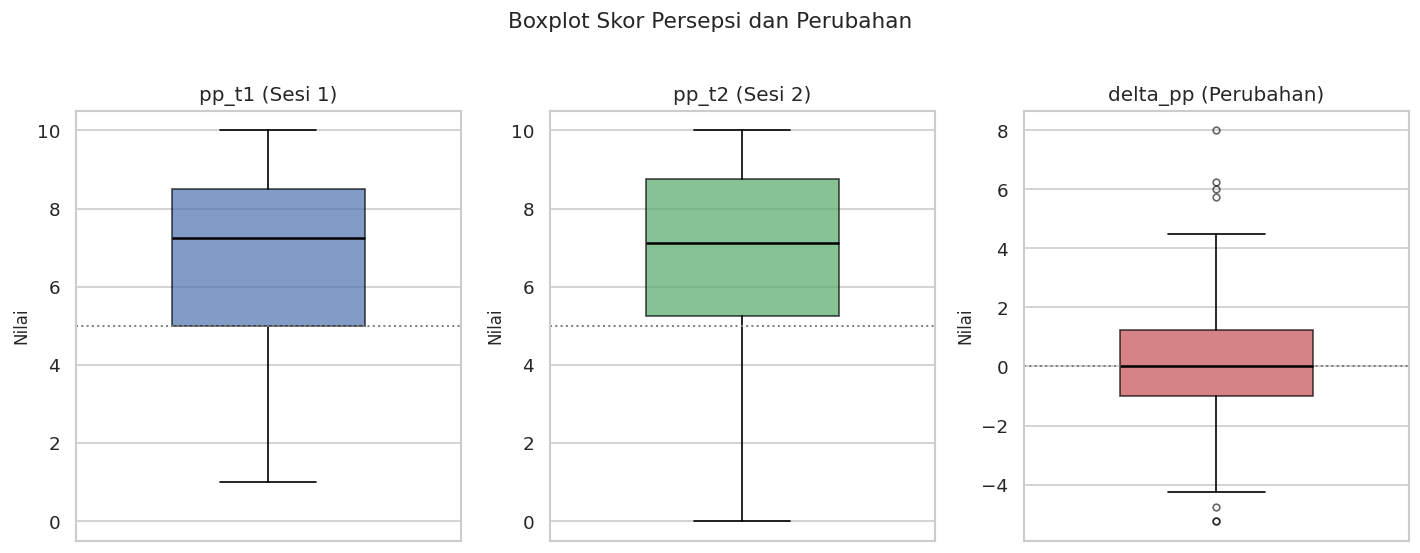

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

for ax, col, warna, judul in zip(
    axes,
    ["pp_t1", "pp_t2", "delta_pp"],
    warna_pp,
    ["pp_t1 (Sesi 1)", "pp_t2 (Sesi 2)", "delta_pp (Perubahan)"]
):
    ax.boxplot(df[col], patch_artist=True, widths=0.5,
               medianprops=dict(color="black", linewidth=1.5),
               boxprops=dict(facecolor=warna, alpha=0.7),
               flierprops=dict(marker="o", markersize=4, alpha=0.6))
    ax.set_title(judul)
    ax.set_ylabel("Nilai")
    ax.set_xticks([])
    if col != "delta_pp":
        ax.axhline(5, color="gray", linestyle=":", linewidth=1.2)
        ax.set_ylim(-0.5, 10.5)
    else:
        ax.axhline(0, color="gray", linestyle=":", linewidth=1.2)

plt.suptitle("Boxplot Skor Persepsi dan Perubahan", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

CELL 11 - Boxplot Perbandingan pp_t1 vs pp_t2

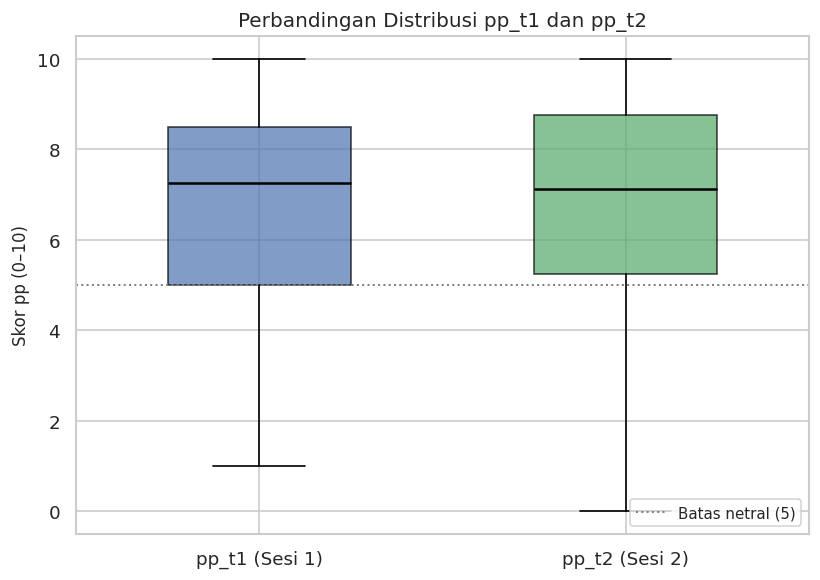

In [47]:
fig, ax = plt.subplots(figsize=(7, 5))
data_box = [df["pp_t1"], df["pp_t2"]]
bp = ax.boxplot(data_box, patch_artist=True, widths=0.5,
                tick_labels=["pp_t1 (Sesi 1)", "pp_t2 (Sesi 2)"],
                medianprops=dict(color="black", linewidth=1.5),
                boxprops=dict(alpha=0.7),
                flierprops=dict(marker="o", markersize=4, alpha=0.6))
bp["boxes"][0].set_facecolor(warna_pp[0])
bp["boxes"][1].set_facecolor(warna_pp[1])
ax.axhline(5, color="gray", linestyle=":", linewidth=1.2, label="Batas netral (5)")
ax.set_ylabel("Skor pp (0–10)")
ax.set_title("Perbandingan Distribusi pp_t1 dan pp_t2")
ax.legend(loc="lower right", fontsize=9)
ax.set_ylim(-0.5, 10.5)
plt.tight_layout()
plt.show()

CELL 12 - Diagram Batang Kategori delta_pp

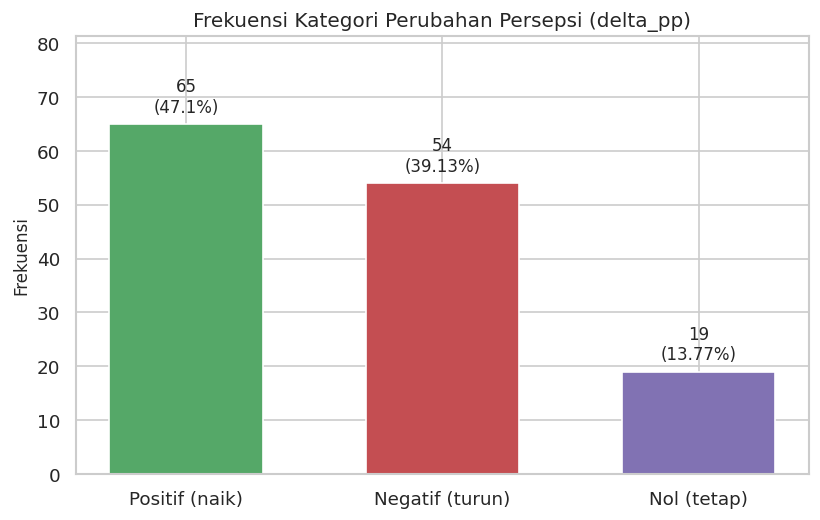

In [48]:
fig, ax = plt.subplots(figsize=(7, 4.5))
urutan = ["Positif (naik)", "Negatif (turun)", "Nol (tetap)"]
warna_bar = ["#55A868", "#C44E52", "#8172B3"]
bars = ax.bar(urutan, freq_delta.values, color=warna_bar, edgecolor="white", width=0.6)

for bar, val, pct in zip(bars, freq_delta.values, freq_delta_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
            f"{val}\n({pct}%)", ha="center", va="bottom", fontsize=10)

ax.set_ylabel("Frekuensi")
ax.set_title("Frekuensi Kategori Perubahan Persepsi (delta_pp)")
ax.set_ylim(0, max(freq_delta.values) * 1.25)
plt.tight_layout()
plt.show()

CELL 13 - Diagram Batang Variabel Kategorik

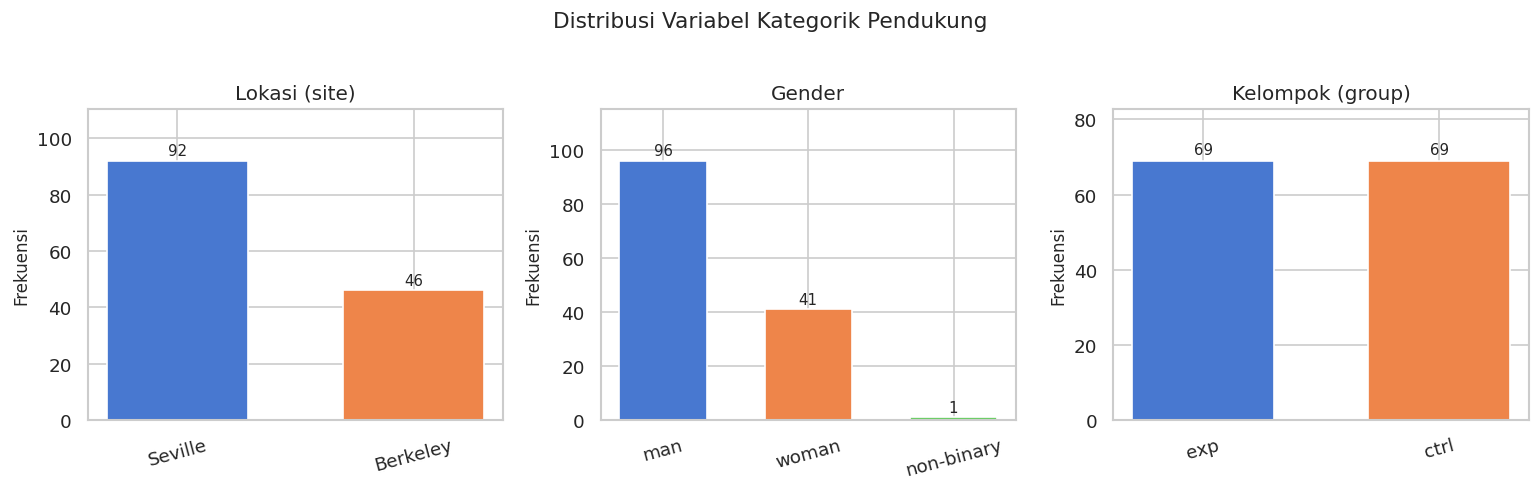

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, col, judul in zip(
    axes,
    ["site", "gender", "group"],
    ["Lokasi (site)", "Gender", "Kelompok (group)"]
):
    vc = df[col].value_counts()
    bars = ax.bar(vc.index.astype(str), vc.values,
                  color=sns.color_palette("muted", len(vc)),
                  edgecolor="white", width=0.6)
    for bar, val in zip(bars, vc.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                str(val), ha="center", va="bottom", fontsize=9)
    ax.set_title(judul)
    ax.set_ylabel("Frekuensi")
    ax.set_ylim(0, max(vc.values) * 1.2)
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Distribusi Variabel Kategorik Pendukung", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

CELL 14 - Boxplot delta_pp per Lokasi

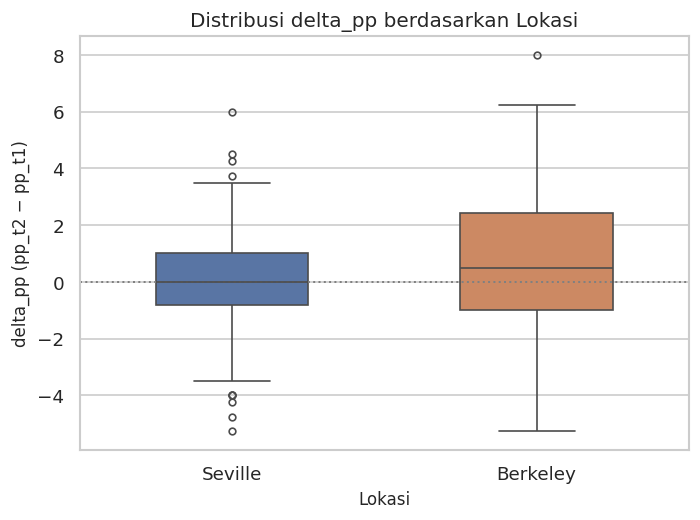

In [50]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=df, x="site", y="delta_pp", hue="site",
            palette=["#4C72B0", "#DD8452"], ax=ax, width=0.5, fliersize=4,
            legend=False)
ax.axhline(0, color="gray", linestyle=":", linewidth=1.2)
ax.set_title("Distribusi delta_pp berdasarkan Lokasi")
ax.set_xlabel("Lokasi")
ax.set_ylabel("delta_pp (pp_t2 − pp_t1)")
plt.tight_layout()
plt.show()

CELL 15 - Interpretasi Deskriptif

In [51]:
print("=" * 70)
print("6. INTERPRETASI DESKRIPTIF (skala pp 0–10)")
print("=" * 70)

mean_t1 = df["pp_t1"].mean()
mean_t2 = df["pp_t2"].mean()
mean_d  = df["delta_pp"].mean()
med_d   = df["delta_pp"].median()

print(f"""
Skala interpretasi skor pp:
  • Nilai > 5  → pair programming dipersepsikan lebih produktif daripada solo
  • Nilai = 5  → pair dan solo dipersepsikan sama
  • Nilai < 5  → solo programming dipersepsikan lebih baik

Temuan deskriptif utama:

1. Persepsi rata-rata setelah sesi 1 (pp_t1):
   Mean = {mean_t1:.3f}, Median = {df['pp_t1'].median():.3f}
   → Rata-rata berada di atas 5, menunjukkan secara keseluruhan peserta
     cenderung mempersepsikan pair programming sedikit lebih baik
     daripada solo setelah sesi pertama.

2. Persepsi rata-rata setelah sesi 2 (pp_t2):
   Mean = {mean_t2:.3f}, Median = {df['pp_t2'].median():.3f}
   → Rata-rata tetap di atas 5 dan sedikit lebih tinggi dibanding t1.

3. Perubahan persepsi (delta_pp = pp_t2 − pp_t1):
   Mean = {mean_d:.3f}, Median = {med_d:.3f}
   → Rata-rata perubahan mendekati nol (sedikit positif).
   → Median tepat 0, artinya separuh peserta tidak mengalami kenaikan
     maupun penurunan persepsi.

4. Arah perubahan (frekuensi):
   • Positif (naik)  : {freq_delta['Positif (naik)']} peserta ({freq_delta_pct['Positif (naik)']}%)
   • Negatif (turun) : {freq_delta['Negatif (turun)']} peserta ({freq_delta_pct['Negatif (turun)']}%)
   • Nol (tetap)     : {freq_delta['Nol (tetap)']} peserta ({freq_delta_pct['Nol (tetap)']}%)
   → Proporsi peserta yang mengalami kenaikan persepsi hampir seimbang
     dengan yang mengalami penurunan; sebagian kecil tetap sama.

5. Variabilitas:
   Standar deviasi delta_pp = {df['delta_pp'].std():.3f}
   Rentang delta_pp = [{df['delta_pp'].min():.2f}, {df['delta_pp'].max():.2f}]
   → Terdapat variasi individu yang cukup besar. Variasi ini wajar
     pada data persepsi self-report.

Catatan metodologis:
- Analisis di atas bersifat deskriptif. Perbedaan mean antara t1 dan t2
  maupun distribusi delta_pp TIDAK dapat diartikan sebagai pengaruh
  kausal dari perlakuan manapun (termasuk group exp/ctrl).
- Semua peserta mengerjakan tugas berpasangan; skor pp mengukur
  persepsi relatif pair vs solo, bukan performa objektif.
""")

6. INTERPRETASI DESKRIPTIF (skala pp 0–10)

Skala interpretasi skor pp:
  • Nilai > 5  → pair programming dipersepsikan lebih produktif daripada solo
  • Nilai = 5  → pair dan solo dipersepsikan sama
  • Nilai < 5  → solo programming dipersepsikan lebih baik

Temuan deskriptif utama:

1. Persepsi rata-rata setelah sesi 1 (pp_t1):
   Mean = 6.647, Median = 7.250
   → Rata-rata berada di atas 5, menunjukkan secara keseluruhan peserta
     cenderung mempersepsikan pair programming sedikit lebih baik
     daripada solo setelah sesi pertama.

2. Persepsi rata-rata setelah sesi 2 (pp_t2):
   Mean = 6.871, Median = 7.125
   → Rata-rata tetap di atas 5 dan sedikit lebih tinggi dibanding t1.

3. Perubahan persepsi (delta_pp = pp_t2 − pp_t1):
   Mean = 0.225, Median = 0.000
   → Rata-rata perubahan mendekati nol (sedikit positif).
   → Median tepat 0, artinya separuh peserta tidak mengalami kenaikan
     maupun penurunan persepsi.

4. Arah perubahan (frekuensi):
   • Positif (naik)  : 65 peserta